In [75]:
import io
import glob

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import librosa

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

In [76]:
# Audio / feature configuration

SAMPLE_RATE = 16000

FRAME_LENGTH = 0.025
FRAME_HOP = 0.020

N_FFT = 400
HOP_LENGTH = 320
N_MELS = 80


# Find dataset files

parquet_files = sorted(
    glob.glob(
        "../data/raw/librispeech-segment/train.clean.100-*.parquet"
    )
)

print("Parquet files:", len(parquet_files))


# Build phoneme vocabulary directly from the dataset

phone_counts = {}

for path in parquet_files:

    table = pq.read_table(
        path,
        columns=["phones"]
    )

    phone_lists = table["phones"].to_pylist()

    for phone_list in phone_lists:
        for phone in phone_list:
            phone_counts[phone] = (
                phone_counts.get(phone, 0) + 1
            )


phones = sorted(phone_counts.keys())

phone_to_id = {
    phone: i
    for i, phone in enumerate(phones)
}

id_to_phone = {
    i: phone
    for phone, i in phone_to_id.items()
}


# Model configuration

NUM_CLASSES = len(phones)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("Number of phoneme classes:", NUM_CLASSES)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("\nPhones:")
print(phones)

Parquet files: 15
Number of phoneme classes: 41
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU

Phones:
['AA', 'AE', 'AH', 'AO', 'AW', 'AY', 'B', 'CH', 'D', 'DH', 'EH', 'ER', 'EY', 'F', 'G', 'HH', 'IH', 'IY', 'JH', 'K', 'L', 'M', 'N', 'NG', 'OW', 'OY', 'P', 'R', 'S', 'SH', 'T', 'TH', 'UH', 'UW', 'V', 'W', 'Y', 'Z', 'ZH', '[SIL]', '[UNK]']


In [77]:
metadata_parts = []

for path in parquet_files:
    table = pq.read_table(
        path,
        columns=["speaker_id"]
    )

    metadata_parts.append(
        table.to_pandas()
    )

metadata = pd.concat(
    metadata_parts,
    ignore_index=True
)

speakers = np.array(
    metadata["speaker_id"].unique().tolist()
)

train_speakers, test_speakers = train_test_split(
    speakers,
    test_size=0.2,
    random_state=42
)

train_speakers = set(train_speakers)
test_speakers = set(test_speakers)

print("Total speakers:", len(speakers))
print("Training speakers:", len(train_speakers))
print("Test speakers:", len(test_speakers))

Total speakers: 251
Training speakers: 200
Test speakers: 51


In [78]:
train_index = []
test_index = []

for file_id, path in enumerate(parquet_files):

    table = pq.read_table(
        path,
        columns=["speaker_id"]
    )

    speakers_in_file = table["speaker_id"].to_pylist()

    for row_id, speaker_id in enumerate(speakers_in_file):

        if speaker_id in train_speakers:
            train_index.append({
                "file_id": file_id,
                "row_id": row_id,
            })

        elif speaker_id in test_speakers:
            test_index.append({
                "file_id": file_id,
                "row_id": row_id,
            })

print("Training examples:", len(train_index))
print("Test examples:", len(test_index))
print("Total:", len(train_index) + len(test_index))

Training examples: 22692
Test examples: 5846
Total: 28538


In [79]:
# ============================================
# Cell 5: Build 1-second chunk indexes
# ============================================

CHUNK_DURATION = 1.0
CHUNK_SAMPLES = int(SAMPLE_RATE * CHUNK_DURATION)

train_chunk_index = []
test_chunk_index = []

for file_id, path in enumerate(parquet_files):

    table = pq.read_table(
        path,
        columns=["speaker_id", "duration"]
    )

    speakers_in_file = table["speaker_id"].to_pylist()
    durations_in_file = table["duration"].to_pylist()

    for row_id, (speaker_id, duration) in enumerate(
        zip(speakers_in_file, durations_in_file)
    ):

        num_chunks = int(
            np.ceil(duration / CHUNK_DURATION)
        )

        for chunk_id in range(num_chunks):

            item = {
                "file_id": file_id,
                "row_id": row_id,
                "chunk_id": chunk_id,
            }

            if speaker_id in train_speakers:
                train_chunk_index.append(item)

            elif speaker_id in test_speakers:
                test_chunk_index.append(item)


print("Training chunks:", len(train_chunk_index))
print("Test chunks:", len(test_chunk_index))
print(
    "Total chunks:",
    len(train_chunk_index) + len(test_chunk_index)
)

Training chunks: 299473
Test chunks: 76638
Total chunks: 376111


In [80]:
# ============================================
# Cell 6: Create processed-data directories
# ============================================

from pathlib import Path

PROCESSED_DIR = Path(
    "../data/processed/phoneme_chunks"
)

TRAIN_FEATURE_DIR = PROCESSED_DIR / "train"
TEST_FEATURE_DIR = PROCESSED_DIR / "test"

TRAIN_FEATURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TEST_FEATURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Processed data directory:")
print(PROCESSED_DIR.resolve())

Processed data directory:
C:\Users\louiz\Documents\Projects\phoneme-lipsync\data\processed\phoneme_chunks


In [81]:
# ============================================
# Cell 7: Audio → Log-Mel + labels
# ============================================

def process_audio_chunk(
    audio_entry,
    duration,
    phones,
    phone_starts,
    phone_ends,
    chunk_id,
):
    """
    Decode one audio file, extract one 1-second chunk,
    compute log-Mel features, and create frame labels.
    """

    # ----------------------------------------
    # Decode audio
    # ----------------------------------------

    audio, sample_rate = sf.read(
        io.BytesIO(audio_entry["bytes"]),
        dtype="float32"
    )

    # Stereo → mono
    if audio.ndim > 1:
        audio = np.mean(
            audio,
            axis=1
        )

    # Resample if necessary
    if sample_rate != SAMPLE_RATE:

        audio = librosa.resample(
            audio,
            orig_sr=sample_rate,
            target_sr=SAMPLE_RATE
        )

    # ----------------------------------------
    # Extract chunk
    # ----------------------------------------

    chunk_start_sample = (
        chunk_id * CHUNK_SAMPLES
    )

    chunk_end_sample = (
        chunk_start_sample + CHUNK_SAMPLES
    )

    chunk = audio[
        chunk_start_sample:chunk_end_sample
    ]

    actual_samples = len(chunk)

    # Pad final chunk
    if actual_samples < CHUNK_SAMPLES:

        chunk = np.pad(
            chunk,
            (
                0,
                CHUNK_SAMPLES - actual_samples
            )
        )

    # ----------------------------------------
    # Log-Mel
    # ----------------------------------------

    log_mel = librosa.feature.melspectrogram(
        y=chunk,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
        center=False,
    )

    log_mel = librosa.power_to_db(
        log_mel,
        ref=np.max
    )

    # ----------------------------------------
    # Create frame labels
    # ----------------------------------------

    chunk_start_time = (
        chunk_start_sample / SAMPLE_RATE
    )

    actual_audio_end = (
        chunk_start_time
        + actual_samples / SAMPLE_RATE
    )

    labels = []

    for frame_index in range(
        log_mel.shape[1]
    ):

        frame_start = (
            chunk_start_time
            + frame_index * FRAME_HOP
        )

        frame_end = (
            frame_start
            + FRAME_LENGTH
        )

        # Padding region
        if frame_start >= actual_audio_end:

            labels.append(-100)
            continue

        # Find phoneme with largest overlap
        best_phone = "[UNK]"
        best_overlap = 0.0

        for phone, phone_start, phone_end in zip(
            phones,
            phone_starts,
            phone_ends
        ):

            overlap_start = max(
                frame_start,
                phone_start
            )

            overlap_end = min(
                frame_end,
                phone_end
            )

            overlap = max(
                0.0,
                overlap_end - overlap_start
            )

            if overlap > best_overlap:

                best_overlap = overlap
                best_phone = phone

        labels.append(
            phone_to_id[best_phone]
        )

    # ----------------------------------------
    # Convert to arrays
    # ----------------------------------------

    X = np.asarray(
        log_mel,
        dtype=np.float32
    )

    y = np.asarray(
        labels,
        dtype=np.int64
    )

    return X, y

In [82]:
# ============================================
# Cell 8: Preprocessing function
# ============================================

from pathlib import Path
import os


def process_audio_chunk(
    audio_entry,
    phones,
    phone_starts,
    phone_ends,
    chunk_id,
    duration,
):
    """
    Decode one audio file and create one 1-second
    log-Mel feature chunk with frame-level labels.
    """

    # ----------------------------------------
    # Decode audio
    # ----------------------------------------

    audio, sample_rate = sf.read(
        io.BytesIO(audio_entry["bytes"]),
        dtype="float32"
    )

    # Stereo -> mono
    if audio.ndim > 1:
        audio = np.mean(audio, axis=1)

    # Resample if necessary
    if sample_rate != SAMPLE_RATE:
        audio = librosa.resample(
            audio,
            orig_sr=sample_rate,
            target_sr=SAMPLE_RATE
        )

    # ----------------------------------------
    # Extract 1-second chunk
    # ----------------------------------------

    chunk_start_sample = (
        chunk_id * CHUNK_SAMPLES
    )

    chunk_end_sample = (
        chunk_start_sample + CHUNK_SAMPLES
    )

    chunk = audio[
        chunk_start_sample:chunk_end_sample
    ]

    actual_samples = len(chunk)

    # Pad final chunk with zeros
    if actual_samples < CHUNK_SAMPLES:
        chunk = np.pad(
            chunk,
            (
                0,
                CHUNK_SAMPLES - actual_samples
            )
        )

    # ----------------------------------------
    # Log-Mel features
    # ----------------------------------------

    log_mel = librosa.feature.melspectrogram(
        y=chunk,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
        center=False,
    )

    log_mel = librosa.power_to_db(
        log_mel,
        ref=np.max
    )

    # ----------------------------------------
    # Frame labels
    # ----------------------------------------

    chunk_start_time = (
        chunk_start_sample / SAMPLE_RATE
    )

    actual_audio_end = (
        chunk_start_time
        + actual_samples / SAMPLE_RATE
    )

    labels = []

    for frame_index in range(log_mel.shape[1]):

        frame_start = (
            chunk_start_time
            + frame_index * FRAME_HOP
        )

        frame_end = (
            frame_start
            + FRAME_LENGTH
        )

        # Ignore frames that are entirely padding
        if frame_start >= actual_audio_end:
            labels.append(-100)
            continue

        best_phone = "[UNK]"
        best_overlap = 0.0

        for phone, phone_start, phone_end in zip(
            phones,
            phone_starts,
            phone_ends
        ):

            overlap_start = max(
                frame_start,
                phone_start
            )

            overlap_end = min(
                frame_end,
                phone_end
            )

            overlap = max(
                0.0,
                overlap_end - overlap_start
            )

            if overlap > best_overlap:
                best_overlap = overlap
                best_phone = phone

        labels.append(
            phone_to_id[best_phone]
        )

    return (
        np.asarray(log_mel, dtype=np.float32),
        np.asarray(labels, dtype=np.int64)
    )

In [83]:
# ============================================
# Cell 9: Sharded preprocessing
# ============================================

SHARD_SIZE = 2000


def process_audio(
    audio_entry,
):
    """
    Decode and resample one utterance once.
    """

    audio, sample_rate = sf.read(
        io.BytesIO(audio_entry["bytes"]),
        dtype="float32"
    )

    if audio.ndim > 1:
        audio = np.mean(audio, axis=1)

    if sample_rate != SAMPLE_RATE:
        audio = librosa.resample(
            audio,
            orig_sr=sample_rate,
            target_sr=SAMPLE_RATE
        )

    return audio


def create_chunk(
    audio,
    phones,
    phone_starts,
    phone_ends,
    chunk_id,
):
    """
    Create one 1-second feature/label chunk.
    """

    chunk_start_sample = chunk_id * CHUNK_SAMPLES
    chunk_end_sample = chunk_start_sample + CHUNK_SAMPLES

    chunk = audio[
        chunk_start_sample:chunk_end_sample
    ]

    actual_samples = len(chunk)

    if actual_samples < CHUNK_SAMPLES:
        chunk = np.pad(
            chunk,
            (0, CHUNK_SAMPLES - actual_samples)
        )

    log_mel = librosa.feature.melspectrogram(
        y=chunk,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0,
        center=False,
    )

    log_mel = librosa.power_to_db(
        log_mel,
        ref=np.max
    )

    chunk_start_time = (
        chunk_start_sample / SAMPLE_RATE
    )

    actual_audio_end = (
        chunk_start_time
        + actual_samples / SAMPLE_RATE
    )

    labels = []

    for frame_index in range(
        log_mel.shape[1]
    ):

        frame_start = (
            chunk_start_time
            + frame_index * FRAME_HOP
        )

        frame_end = (
            frame_start + FRAME_LENGTH
        )

        if frame_start >= actual_audio_end:
            labels.append(-100)
            continue

        best_phone = "[UNK]"
        best_overlap = 0.0

        for phone, phone_start, phone_end in zip(
            phones,
            phone_starts,
            phone_ends
        ):

            overlap_start = max(
                frame_start,
                phone_start
            )

            overlap_end = min(
                frame_end,
                phone_end
            )

            overlap = max(
                0.0,
                overlap_end - overlap_start
            )

            if overlap > best_overlap:
                best_overlap = overlap
                best_phone = phone

        labels.append(
            phone_to_id[best_phone]
        )

    return (
        np.asarray(log_mel, dtype=np.float32),
        np.asarray(labels, dtype=np.int64)
    )

In [84]:
# ============================================
# Cell 10: Preprocess split into shards
# ============================================

def preprocess_split(
    chunk_index,
    output_dir,
    split_name,
):
    """
    Preprocess a split and save data in shards.

    Each shard contains SHARD_SIZE chunks.
    """

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Group chunks by Parquet file
    chunks_by_file = {}

    for item in chunk_index:

        file_id = item["file_id"]

        if file_id not in chunks_by_file:
            chunks_by_file[file_id] = []

        chunks_by_file[file_id].append(item)

    total_chunks = len(chunk_index)

    # Global chunk counter
    processed_chunks = 0

    # Current shard
    shard_X = []
    shard_y = []
    shard_id = 0

    print(
        f"Starting {split_name} preprocessing..."
    )

    print(
        f"Total chunks: {total_chunks}"
    )

    for file_number, file_id in enumerate(
        sorted(chunks_by_file.keys()),
        start=1
    ):

        path = parquet_files[file_id]

        print(
            f"\nFile {file_number}/"
            f"{len(chunks_by_file)}: "
            f"{Path(path).name}"
        )

        table = pq.read_table(
            path,
            columns=[
                "audio",
                "duration",
                "phones",
                "phone_starts",
                "phone_ends",
            ]
        )

        # Group chunks by utterance
        chunks_by_row = {}

        for item in chunks_by_file[file_id]:

            row_id = item["row_id"]

            if row_id not in chunks_by_row:
                chunks_by_row[row_id] = []

            chunks_by_row[row_id].append(
                item["chunk_id"]
            )

        for row_id, chunk_ids in chunks_by_row.items():

            # Decode this utterance ONCE
            audio_entry = (
                table["audio"][row_id].as_py()
            )

            audio = process_audio(
                audio_entry
            )

            phones = (
                table["phones"][row_id].as_py()
            )

            phone_starts = (
                table["phone_starts"][row_id].as_py()
            )

            phone_ends = (
                table["phone_ends"][row_id].as_py()
            )

            # Create all chunks from this utterance
            for chunk_id in sorted(chunk_ids):

                X, y = create_chunk(
                    audio=audio,
                    phones=phones,
                    phone_starts=phone_starts,
                    phone_ends=phone_ends,
                    chunk_id=chunk_id,
                )

                shard_X.append(X)
                shard_y.append(y)

                processed_chunks += 1

                # Save shard
                if len(shard_X) >= SHARD_SIZE:

                    shard_path = (
                        output_dir
                        / f"shard_{shard_id:05d}.npz"
                    )

                    np.savez_compressed(
                        shard_path,
                        X=np.stack(shard_X),
                        y=np.stack(shard_y),
                    )

                    print(
                        f"Saved {shard_path.name} "
                        f"({len(shard_X)} chunks)"
                    )

                    shard_X = []
                    shard_y = []
                    shard_id += 1

        del table

        print(
            f"Processed: "
            f"{processed_chunks}/{total_chunks}"
        )

    # Save final partial shard
    if len(shard_X) > 0:

        shard_path = (
            output_dir
            / f"shard_{shard_id:05d}.npz"
        )

        np.savez_compressed(
            shard_path,
            X=np.stack(shard_X),
            y=np.stack(shard_y),
        )

        print(
            f"Saved {shard_path.name} "
            f"({len(shard_X)} chunks)"
        )

    print(
        f"\nFinished {split_name} preprocessing."
    )

    print(
        f"Total chunks saved: "
        f"{processed_chunks}"
    )

In [85]:
# ============================================
# Cell 11: Test sharded preprocessing
# ============================================

TEST_SHARD_DIR = (
    Path("../data/processed/phoneme_chunks_test")
)

TEST_SHARD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

small_test_index = train_chunk_index[:2000]

preprocess_split(
    chunk_index=small_test_index,
    output_dir=TEST_SHARD_DIR,
    split_name="TEST"
)

Starting TEST preprocessing...
Total chunks: 2000

File 1/1: train.clean.100-00000-of-00015.parquet
Saved shard_00000.npz (2000 chunks)
Processed: 2000/2000

Finished TEST preprocessing.
Total chunks saved: 2000


In [86]:
# ============================================
# Cell 12: Inspect test shard
# ============================================

shard_path = (
    TEST_SHARD_DIR
    / "shard_00000.npz"
)

shard = np.load(shard_path)

X_test = shard["X"]
y_test = shard["y"]

print("X shape:", X_test.shape)
print("y shape:", y_test.shape)

print("X dtype:", X_test.dtype)
print("y dtype:", y_test.dtype)

print(
    "Ignored labels:",
    np.sum(y_test == -100)
)

X shape: (2000, 80, 49)
y shape: (2000, 49)
X dtype: float32
y dtype: int64
Ignored labels: 3362


In [87]:
# ============================================
# Cell 13: Preprocess training set
# ============================================

TRAIN_FEATURE_DIR = Path(
    "../data/processed/phoneme_chunks/train"
)

preprocess_split(
    chunk_index=train_chunk_index,
    output_dir=TRAIN_FEATURE_DIR,
    split_name="TRAIN"
)

Starting TRAIN preprocessing...
Total chunks: 299473

File 1/15: train.clean.100-00000-of-00015.parquet
Saved shard_00000.npz (2000 chunks)
Saved shard_00001.npz (2000 chunks)
Saved shard_00002.npz (2000 chunks)
Saved shard_00003.npz (2000 chunks)
Saved shard_00004.npz (2000 chunks)
Saved shard_00005.npz (2000 chunks)
Saved shard_00006.npz (2000 chunks)
Saved shard_00007.npz (2000 chunks)
Saved shard_00008.npz (2000 chunks)
Processed: 18554/299473

File 2/15: train.clean.100-00001-of-00015.parquet
Saved shard_00009.npz (2000 chunks)
Saved shard_00010.npz (2000 chunks)
Saved shard_00011.npz (2000 chunks)
Saved shard_00012.npz (2000 chunks)
Saved shard_00013.npz (2000 chunks)
Saved shard_00014.npz (2000 chunks)
Saved shard_00015.npz (2000 chunks)
Saved shard_00016.npz (2000 chunks)
Processed: 35923/299473

File 3/15: train.clean.100-00002-of-00015.parquet
Saved shard_00017.npz (2000 chunks)
Saved shard_00018.npz (2000 chunks)
Saved shard_00019.npz (2000 chunks)
Saved shard_00020.npz (200

In [89]:
# ============================================
# Cell 14: Preprocess test set
# ============================================

TEST_FEATURE_DIR = Path(
    "../data/processed/phoneme_chunks/test"
)

preprocess_split(
    chunk_index=test_chunk_index,
    output_dir=TEST_FEATURE_DIR,
    split_name="TEST"
)

Starting TEST preprocessing...
Total chunks: 76638

File 1/15: train.clean.100-00000-of-00015.parquet
Saved shard_00000.npz (2000 chunks)
Saved shard_00001.npz (2000 chunks)
Saved shard_00002.npz (2000 chunks)
Processed: 7839/76638

File 2/15: train.clean.100-00001-of-00015.parquet
Saved shard_00003.npz (2000 chunks)
Saved shard_00004.npz (2000 chunks)
Saved shard_00005.npz (2000 chunks)
Saved shard_00006.npz (2000 chunks)
Saved shard_00007.npz (2000 chunks)
Processed: 17216/76638

File 3/15: train.clean.100-00002-of-00015.parquet
Saved shard_00008.npz (2000 chunks)
Saved shard_00009.npz (2000 chunks)
Processed: 20347/76638

File 4/15: train.clean.100-00003-of-00015.parquet
Saved shard_00010.npz (2000 chunks)
Saved shard_00011.npz (2000 chunks)
Saved shard_00012.npz (2000 chunks)
Processed: 26221/76638

File 5/15: train.clean.100-00004-of-00015.parquet
Saved shard_00013.npz (2000 chunks)
Saved shard_00014.npz (2000 chunks)
Saved shard_00015.npz (2000 chunks)
Processed: 32359/76638

Fil

In [90]:
# ============================================
# Cell 15: Verify train and test shards
# ============================================

def inspect_shards(directory, expected_chunks, name):
    
    shard_files = sorted(
        Path(directory).glob("shard_*.npz")
    )

    print(f"\n{name}")
    print("-" * 40)
    print("Number of shards:", len(shard_files))

    total_chunks = 0

    for path in shard_files:
        with np.load(path) as shard:
            X = shard["X"]
            y = shard["y"]

            total_chunks += X.shape[0]

    print("Total processed chunks:", total_chunks)
    print("Expected chunks:", expected_chunks)
    print("Match:", total_chunks == expected_chunks)

    # Inspect first shard
    with np.load(shard_files[0]) as shard:
        print("First X shape:", shard["X"].shape)
        print("First y shape:", shard["y"].shape)

    # Inspect last shard
    with np.load(shard_files[-1]) as shard:
        print("Last X shape:", shard["X"].shape)
        print("Last y shape:", shard["y"].shape)


inspect_shards(
    TRAIN_FEATURE_DIR,
    len(train_chunk_index),
    "TRAIN"
)

inspect_shards(
    TEST_FEATURE_DIR,
    len(test_chunk_index),
    "TEST"
)


TRAIN
----------------------------------------
Number of shards: 150
Total processed chunks: 299473
Expected chunks: 299473
Match: True
First X shape: (2000, 80, 49)
First y shape: (2000, 49)
Last X shape: (1473, 80, 49)
Last y shape: (1473, 49)

TEST
----------------------------------------
Number of shards: 39
Total processed chunks: 76638
Expected chunks: 76638
Match: True
First X shape: (2000, 80, 49)
First y shape: (2000, 49)
Last X shape: (638, 80, 49)
Last y shape: (638, 49)


In [91]:
# ============================================
# Cell 16: Shard-based PyTorch Dataset
# ============================================

class PhonemeShardDataset(Dataset):

    def __init__(self, shard_dir):

        self.shard_dir = Path(shard_dir)

        self.shard_files = sorted(
            self.shard_dir.glob("shard_*.npz")
        )

        if not self.shard_files:
            raise RuntimeError(
                f"No shard files found in {self.shard_dir}"
            )

        # Get number of samples in each shard
        self.shard_sizes = []

        for path in self.shard_files:

            with np.load(path) as shard:
                self.shard_sizes.append(
                    shard["X"].shape[0]
                )

        self.cumulative_sizes = np.cumsum(
            self.shard_sizes
        )

        self.total_size = int(
            self.cumulative_sizes[-1]
        )

        # Cache for the most recently accessed shard
        self.cached_shard_id = None
        self.cached_X = None
        self.cached_y = None

    def __len__(self):

        return self.total_size

    def _load_shard(self, shard_id):

        if shard_id == self.cached_shard_id:
            return

        shard = np.load(
            self.shard_files[shard_id]
        )

        self.cached_X = shard["X"]
        self.cached_y = shard["y"]

        shard.close()

        self.cached_shard_id = shard_id

    def __getitem__(self, index):

        if index < 0:
            index += self.total_size

        if index < 0 or index >= self.total_size:
            raise IndexError(
                "Dataset index out of range"
            )

        # Find the shard containing this sample
        shard_id = np.searchsorted(
            self.cumulative_sizes,
            index,
            side="right"
        )

        # Convert global index → index inside shard
        if shard_id == 0:
            local_index = index
        else:
            local_index = (
                index
                - self.cumulative_sizes[shard_id - 1]
            )

        # Load/cached shard
        self._load_shard(shard_id)

        X = self.cached_X[local_index]
        y = self.cached_y[local_index]

        return (
            torch.from_numpy(X).float(),
            torch.from_numpy(y).long()
        )

In [92]:
# ============================================
# Cell 16b: Test Dataset
# ============================================

train_dataset = PhonemeShardDataset(
    TRAIN_FEATURE_DIR
)

test_dataset = PhonemeShardDataset(
    TEST_FEATURE_DIR
)

print("Training examples:", len(train_dataset))
print("Test examples:", len(test_dataset))

X, y = train_dataset[0]

print("\nSample:")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X dtype:", X.dtype)
print("y dtype:", y.dtype)

Training examples: 299473
Test examples: 76638

Sample:
X shape: torch.Size([80, 49])
y shape: torch.Size([49])
X dtype: torch.float32
y dtype: torch.int64


In [93]:
# ============================================
# Cell 17: DataLoaders
# ============================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Batch size: 16
Training batches: 18718
Test batches: 4790


In [94]:
# ============================================
# Cell 17b: Test DataLoader
# ============================================

X_batch, y_batch = next(iter(train_loader))

print("X batch shape:", X_batch.shape)
print("y batch shape:", y_batch.shape)
print("X dtype:", X_batch.dtype)
print("y dtype:", y_batch.dtype)

X batch shape: torch.Size([16, 80, 49])
y batch shape: torch.Size([16, 49])
X dtype: torch.float32
y dtype: torch.int64


In [95]:
# ============================================
# Cell 18: CNN-GRU Model
# ============================================

class CNNGRU(nn.Module):

    def __init__(
        self,
        num_classes,
        hidden_size=128,
    ):
        super().__init__()

        # CNN extracts local time-frequency patterns
        self.cnn = nn.Sequential(

            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1,
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(),

            # Reduce frequency dimension
            # Keep time dimension unchanged
            nn.MaxPool2d(
                kernel_size=(2, 1)
            ),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1,
            ),

            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Reduce frequency dimension again
            nn.MaxPool2d(
                kernel_size=(2, 1)
            ),
        )

        # 80 Mel bins
        # ↓ 40
        # ↓ 20
        #
        # 64 CNN channels × 20 frequency bins
        cnn_feature_size = 64 * 20

        # GRU models temporal context
        self.gru = nn.GRU(
            input_size=cnn_feature_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        # Predict one phoneme for each time frame
        self.classifier = nn.Linear(
            hidden_size,
            num_classes,
        )

    def forward(self, x):

        # Input:
        # [batch, 80, 49]

        x = x.unsqueeze(1)

        # [batch, 1, 80, 49]
        x = self.cnn(x)

        # [batch, 64, 20, 49]

        # Move time dimension forward
        x = x.permute(
            0, 3, 1, 2
        )

        # [batch, 49, 64, 20]

        # Flatten CNN features
        x = x.flatten(
            start_dim=2
        )

        # [batch, 49, 1280]

        # Temporal modeling
        x, _ = self.gru(x)

        # [batch, 49, 128]

        # Phoneme classification
        x = self.classifier(x)

        # [batch, 49, num_classes]

        return x

In [96]:
# ============================================
# Cell 18b: Create Model
# ============================================

model = CNNGRU(
    num_classes=NUM_CLASSES,
    hidden_size=128,
).to(DEVICE)

print(model)

CNNGRU(
  (cnn): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
  )
  (gru): GRU(1280, 128, batch_first=True)
  (classifier): Linear(in_features=128, out_features=41, bias=True)
)


In [97]:
# ============================================
# Cell 18c: Test Forward Pass
# ============================================

X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(DEVICE)

with torch.no_grad():
    output = model(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", output.shape)
print("Device:", output.device)

Input shape: torch.Size([16, 80, 49])
Output shape: torch.Size([16, 49, 41])
Device: cuda:0


In [98]:
# ============================================
# Cell 19: Loss Function + Optimizer
# ============================================

criterion = nn.CrossEntropyLoss(
    ignore_index=-100
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [99]:
# ============================================
# Cell 20: Training Sanity Check
# ============================================

model.train()

num_test_batches = 200
running_loss = 0.0

for batch_index, (X_batch, y_batch) in enumerate(train_loader):

    if batch_index >= num_test_batches:
        break

    X_batch = X_batch.to(
        DEVICE,
        non_blocking=True
    )

    y_batch = y_batch.to(
        DEVICE,
        non_blocking=True
    )

    optimizer.zero_grad()

    # Forward pass
    outputs = model(X_batch)

    # [B, 49, NUM_CLASSES]
    # →
    # [B*49, NUM_CLASSES]

    loss = criterion(
        outputs.reshape(-1, NUM_CLASSES),
        y_batch.reshape(-1)
    )

    # Backpropagation
    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    if (batch_index + 1) % 20 == 0:
        average_loss = (
            running_loss / (batch_index + 1)
        )

        print(
            f"Batch {batch_index + 1:3d}/"
            f"{num_test_batches} | "
            f"Loss: {average_loss:.4f}"
        )

print("\nSanity check complete.")

Batch  20/200 | Loss: 2.9851
Batch  40/200 | Loss: 2.7790
Batch  60/200 | Loss: 2.6150
Batch  80/200 | Loss: 2.5124
Batch 100/200 | Loss: 2.4153
Batch 120/200 | Loss: 2.3506
Batch 140/200 | Loss: 2.2843
Batch 160/200 | Loss: 2.2430
Batch 180/200 | Loss: 2.2027
Batch 200/200 | Loss: 2.1646

Sanity check complete.


In [100]:
# ============================================
# Cell 21: Shard-aware Batch Sampler
# ============================================

from torch.utils.data import Sampler


class ShardBatchSampler(Sampler):

    def __init__(
        self,
        dataset,
        batch_size,
        shuffle=True,
        drop_last=False,
    ):
        self.dataset = dataset
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.drop_last = drop_last

        # Build global index ranges for each shard
        self.shard_ranges = []

        start = 0

        for shard_size in dataset.shard_sizes:

            end = start + shard_size

            self.shard_ranges.append(
                (start, end)
            )

            start = end

    def __iter__(self):

        shard_order = list(
            range(len(self.shard_ranges))
        )

        if self.shuffle:
            np.random.shuffle(shard_order)

        for shard_id in shard_order:

            start, end = self.shard_ranges[shard_id]

            indices = np.arange(
                start,
                end
            )

            # Shuffle samples inside the shard
            if self.shuffle:
                np.random.shuffle(indices)

            # Create batches from this shard
            for batch_start in range(
                0,
                len(indices),
                self.batch_size
            ):

                batch = indices[
                    batch_start:
                    batch_start + self.batch_size
                ]

                if (
                    len(batch) < self.batch_size
                    and self.drop_last
                ):
                    continue

                yield batch.tolist()

    def __len__(self):

        total_batches = 0

        for shard_size in self.dataset.shard_sizes:

            if self.drop_last:
                total_batches += (
                    shard_size // self.batch_size
                )
            else:
                total_batches += int(
                    np.ceil(
                        shard_size / self.batch_size
                    )
                )

        return total_batches

In [101]:
# ============================================
# Cell 22: Optimized DataLoaders
# ============================================

BATCH_SIZE = 32

train_batch_sampler = ShardBatchSampler(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
)

test_batch_sampler = ShardBatchSampler(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)

train_loader = DataLoader(
    train_dataset,
    batch_sampler=train_batch_sampler,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_sampler=test_batch_sampler,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))

Batch size: 32
Training batches: 9434
Test batches: 2414


In [102]:
# ============================================
# Cell 23: Test Optimized DataLoader
# ============================================

X_batch, y_batch = next(iter(train_loader))

print("X batch shape:", X_batch.shape)
print("y batch shape:", y_batch.shape)
print("X dtype:", X_batch.dtype)
print("y dtype:", y_batch.dtype)

X batch shape: torch.Size([32, 80, 49])
y batch shape: torch.Size([32, 49])
X dtype: torch.float32
y dtype: torch.int64


In [104]:
# ============================================
# Cell 24: 50-Batch Training Benchmark
# ============================================

model.train()

num_test_batches = 50
running_loss = 0.0

start_time = time.perf_counter()

for batch_index, (X_batch, y_batch) in enumerate(
    train_loader
):

    if batch_index >= num_test_batches:
        break

    X_batch = X_batch.to(
        DEVICE,
        non_blocking=True
    )

    y_batch = y_batch.to(
        DEVICE,
        non_blocking=True
    )

    optimizer.zero_grad()

    # Forward pass
    outputs = model(X_batch)

    loss = criterion(
        outputs.reshape(-1, NUM_CLASSES),
        y_batch.reshape(-1)
    )

    # Backpropagation
    loss.backward()

    optimizer.step()

    running_loss += loss.item()

    # Wait for GPU operations to finish
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    if (batch_index + 1) % 10 == 0:

        average_loss = (
            running_loss / (batch_index + 1)
        )

        print(
            f"Batch {batch_index + 1:2d}/"
            f"{num_test_batches} | "
            f"Loss: {average_loss:.4f}"
        )

elapsed = time.perf_counter() - start_time

print("\nBenchmark complete.")
print(
    f"Total time: {elapsed / 60:.2f} minutes"
)
print(
    f"Average time per batch: "
    f"{elapsed / num_test_batches:.3f} seconds"
)
print(
    f"Batches per second: "
    f"{num_test_batches / elapsed:.2f}"
)

Batch 10/50 | Loss: 1.4789
Batch 20/50 | Loss: 1.4842
Batch 30/50 | Loss: 1.4571
Batch 40/50 | Loss: 1.4515
Batch 50/50 | Loss: 1.4416

Benchmark complete.
Total time: 0.02 minutes
Average time per batch: 0.023 seconds
Batches per second: 43.10


In [110]:
# ============================================
# Cell 25: Fresh Model + Optimizer
# ============================================

# Recreate model from scratch
model = CNNGRU(
    num_classes=NUM_CLASSES,
    hidden_size=128,
).to(DEVICE)

# Fresh optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

# Loss function
criterion = nn.CrossEntropyLoss(
    ignore_index=-100
)

print("Fresh model created.")
print("Optimizer reset.")
print("Loss function reset.")
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Fresh model created.
Optimizer reset.
Loss function reset.
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [111]:
# ============================================
# Cell 26: Full Training
# ============================================

EPOCHS = 5

best_loss = float("inf")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    num_batches = 0

    start_time = time.perf_counter()

    for batch_index, (X_batch, y_batch) in enumerate(
        train_loader
    ):

        X_batch = X_batch.to(
            DEVICE,
            non_blocking=True
        )

        y_batch = y_batch.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Calculate loss
        loss = criterion(
            outputs.reshape(-1, NUM_CLASSES),
            y_batch.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        num_batches += 1

        if (batch_index + 1) % 500 == 0:

            average_loss = (
                running_loss / num_batches
            )

            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_index + 1}/"
                f"{len(train_loader)} | "
                f"Loss: {average_loss:.4f}"
            )

    epoch_loss = (
        running_loss / num_batches
    )

    epoch_time = (
        time.perf_counter() - start_time
    )

    print(
        f"\nEpoch {epoch + 1} complete | "
        f"Loss: {epoch_loss:.4f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

    # Save best model
    if epoch_loss < best_loss:

        best_loss = epoch_loss

        torch.save(
            model.state_dict(),
            "../checkpoints/best_model.pt"
        )

        print(
            f"Saved best model "
            f"(loss: {best_loss:.4f})"
        )

    print()

Epoch 1/5 | Batch 500/9434 | Loss: 1.5869
Epoch 1/5 | Batch 1000/9434 | Loss: 1.4369
Epoch 1/5 | Batch 1500/9434 | Loss: 1.3281
Epoch 1/5 | Batch 2000/9434 | Loss: 1.2759
Epoch 1/5 | Batch 2500/9434 | Loss: 1.2299
Epoch 1/5 | Batch 3000/9434 | Loss: 1.1920
Epoch 1/5 | Batch 3500/9434 | Loss: 1.1700
Epoch 1/5 | Batch 4000/9434 | Loss: 1.1485
Epoch 1/5 | Batch 4500/9434 | Loss: 1.1287
Epoch 1/5 | Batch 5000/9434 | Loss: 1.1085
Epoch 1/5 | Batch 5500/9434 | Loss: 1.0954
Epoch 1/5 | Batch 6000/9434 | Loss: 1.0828
Epoch 1/5 | Batch 6500/9434 | Loss: 1.0699
Epoch 1/5 | Batch 7000/9434 | Loss: 1.0608
Epoch 1/5 | Batch 7500/9434 | Loss: 1.0493
Epoch 1/5 | Batch 8000/9434 | Loss: 1.0405
Epoch 1/5 | Batch 8500/9434 | Loss: 1.0307
Epoch 1/5 | Batch 9000/9434 | Loss: 1.0247

Epoch 1 complete | Loss: 1.0189 | Time: 2.63 min
Saved best model (loss: 1.0189)

Epoch 2/5 | Batch 500/9434 | Loss: 0.8492
Epoch 2/5 | Batch 1000/9434 | Loss: 0.8165
Epoch 2/5 | Batch 1500/9434 | Loss: 0.8201
Epoch 2/5 | Batc

In [120]:
# ============================================
# Cell 27: Load Best Model
# ============================================

checkpoint_path = "../checkpoints/best_model.pt"

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=DEVICE
    )
)

model.to(DEVICE)
model.eval()

print("Best model loaded.")
print("Checkpoint:", checkpoint_path)
print("Device:", DEVICE)

Best model loaded.
Checkpoint: ../checkpoints/best_model.pt
Device: cuda


In [121]:
# ============================================
# Cell 28: Test Evaluation
# ============================================

model.eval()

test_loss = 0.0
correct_frames = 0
total_frames = 0
num_batches = 0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(
            DEVICE,
            non_blocking=True
        )

        y_batch = y_batch.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(X_batch)

        loss = criterion(
            outputs.reshape(-1, NUM_CLASSES),
            y_batch.reshape(-1)
        )

        test_loss += loss.item()
        num_batches += 1

        # Predicted phoneme
        predictions = outputs.argmax(
            dim=-1
        )

        # Ignore padded frames
        valid_mask = (
            y_batch != -100
        )

        correct_frames += (
            (
                predictions[valid_mask]
                == y_batch[valid_mask]
            )
            .sum()
            .item()
        )

        total_frames += (
            valid_mask
            .sum()
            .item()
        )

average_test_loss = (
    test_loss / num_batches
)

test_accuracy = (
    correct_frames / total_frames
)

print("Evaluation complete.")
print(
    f"Test loss: {average_test_loss:.4f}"
)
print(
    f"Frame accuracy: "
    f"{test_accuracy * 100:.2f}%"
)
print(
    f"Correct frames: {correct_frames:,}"
)
print(
    f"Total valid frames: {total_frames:,}"
)

Evaluation complete.
Test loss: 1.0060
Frame accuracy: 69.25%
Correct frames: 2,507,206
Total valid frames: 3,620,613


In [122]:
# ============================================
# Cell 29: Phoneme Confusion Matrix
# ============================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(
            DEVICE,
            non_blocking=True
        )

        y_batch = y_batch.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(X_batch)

        predictions = outputs.argmax(
            dim=-1
        )

        # Ignore padded frames
        valid_mask = (
            y_batch != -100
        )

        all_predictions.extend(
            predictions[valid_mask]
            .cpu()
            .numpy()
        )

        all_targets.extend(
            y_batch[valid_mask]
            .cpu()
            .numpy()
        )

all_predictions = np.asarray(
    all_predictions
)

all_targets = np.asarray(
    all_targets
)

cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=range(NUM_CLASSES)
)

print("Predictions collected:", len(all_predictions))
print("Confusion matrix shape:", cm.shape)

Predictions collected: 3620613
Confusion matrix shape: (41, 41)


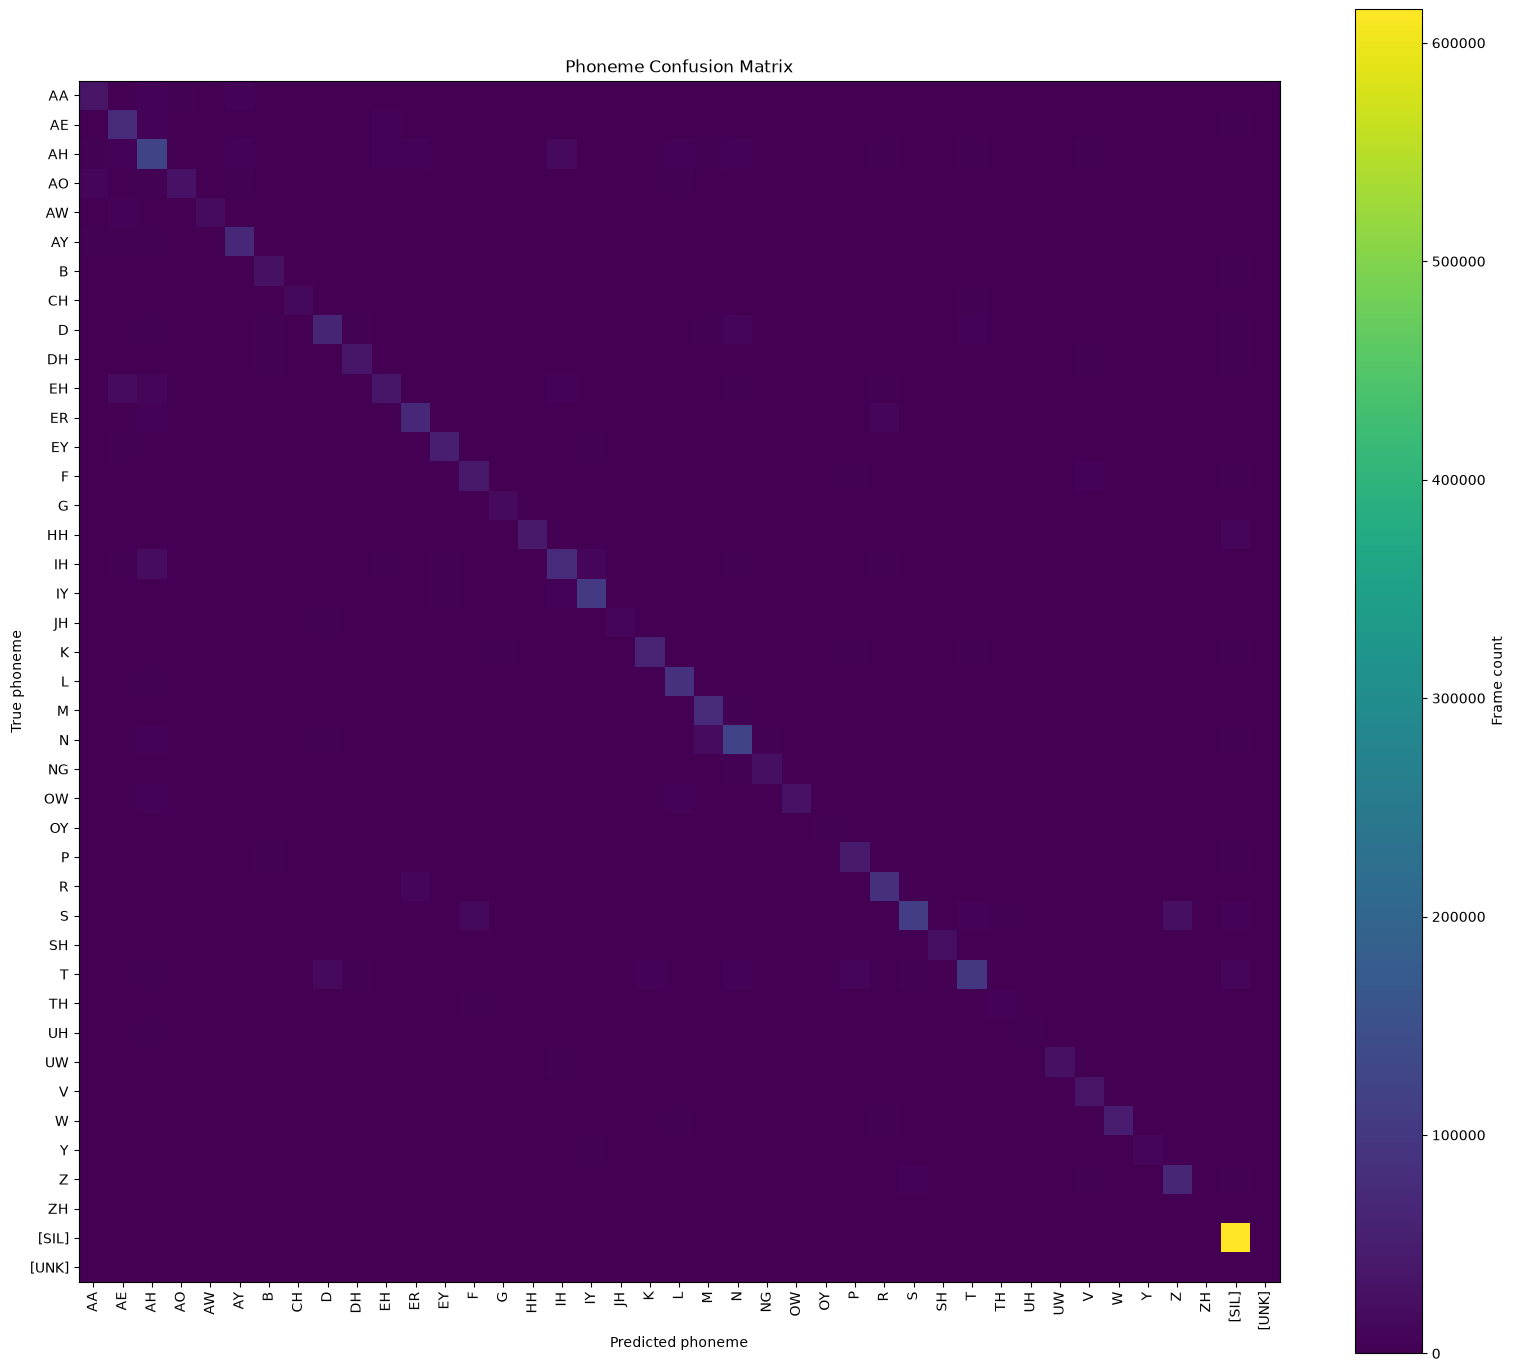

In [123]:
# ============================================
# Cell 30: Plot Confusion Matrix
# ============================================

fig, ax = plt.subplots(
    figsize=(16, 14)
)

im = ax.imshow(
    cm,
    interpolation="nearest"
)

ax.set_title(
    "Phoneme Confusion Matrix"
)

ax.set_xlabel(
    "Predicted phoneme"
)

ax.set_ylabel(
    "True phoneme"
)

ax.set_xticks(
    range(NUM_CLASSES)
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_xticklabels(
    phones,
    rotation=90
)

ax.set_yticklabels(
    phones
)

plt.colorbar(
    im,
    ax=ax,
    label="Frame count"
)

plt.tight_layout()
plt.show()

In [124]:
# ============================================
# Cell 31: Per-Phoneme Accuracy
# ============================================

print("Per-phoneme accuracy")
print("=" * 50)

per_phone_results = []

for phone_id, phone in id_to_phone.items():

    true_mask = (
        all_targets == phone_id
    )

    total = true_mask.sum()

    if total == 0:
        continue

    correct = (
        all_predictions[true_mask]
        == phone_id
    ).sum()

    accuracy = correct / total

    per_phone_results.append({
        "phone": phone,
        "accuracy": accuracy,
        "correct": int(correct),
        "total": int(total),
    })

per_phone_results = sorted(
    per_phone_results,
    key=lambda x: x["accuracy"]
)

for result in per_phone_results:

    print(
        f"{result['phone']:>5} | "
        f"{result['accuracy'] * 100:6.2f}% | "
        f"{result['correct']:7,d} / "
        f"{result['total']:7,d}"
    )

Per-phoneme accuracy
[UNK] |   0.00% |       0 /  16,757
   UH |  22.02% |   2,647 /  12,019
   TH |  28.85% |   6,285 /  21,784
   EH |  42.70% |  37,852 /  88,656
   ZH |  43.35% |     629 /   1,451
   JH |  45.88% |   7,646 /  16,667
   AO |  49.47% |  29,624 /  59,877
   IH |  49.74% |  73,301 / 147,382
   OY |  50.95% |   3,280 /   6,438
    Y |  51.52% |   9,025 /  17,517
   OW |  51.78% |  30,188 /  58,297
   CH |  52.85% |  12,289 /  23,253
    T |  54.58% |  97,787 / 179,159
    D |  55.74% |  64,657 / 116,006
   HH |  56.34% |  42,077 /  74,684
   AW |  56.63% |  18,130 /  32,015
   DH |  56.95% |  35,088 /  61,613
   AH |  57.65% | 126,585 / 219,562
   AA |  58.29% |  31,284 /  53,674
    G |  60.55% |  14,431 /  23,835
    S |  62.25% | 112,288 / 180,379
    F |  63.18% |  41,458 /  65,617
   UW |  63.52% |  28,848 /  45,415
    B |  64.04% |  27,333 /  42,682
    V |  67.40% |  32,461 /  48,165
   ER |  69.11% |  71,510 / 103,474
   AE |  70.07% |  75,957 / 108,399
    W |

In [125]:
# ============================================
# Cell 32: Biggest Phoneme Confusions
# ============================================

confusions = []

for true_id in range(NUM_CLASSES):

    for predicted_id in range(NUM_CLASSES):

        if true_id == predicted_id:
            continue

        count = cm[true_id, predicted_id]

        if count > 0:

            confusions.append({
                "true": id_to_phone[true_id],
                "predicted": id_to_phone[predicted_id],
                "count": int(count),
            })

confusions = sorted(
    confusions,
    key=lambda x: x["count"],
    reverse=True
)

print("Top 30 phoneme confusions")
print("=" * 50)

for confusion in confusions[:30]:

    print(
        f"{confusion['true']:>5} → "
        f"{confusion['predicted']:<5} "
        f"{confusion['count']:>8,d}"
    )

Top 30 phoneme confusions
    S → Z       24,635
   IH → AH      19,855
    N → M       18,874
   EH → AE      18,704
    T → D       16,705
   AH → IH      14,715
    S → F       12,067
   ER → R       11,718
    D → N       11,668
   AO → AA      11,452
    R → ER       9,564
   HH → [SIL]    9,476
    T → P        9,225
   IH → IY       8,218
    T → [SIL]    8,046
   EH → AH       7,429
   AH → N        7,178
    D → T        7,176
   OW → L        6,721
    S → [SIL]    6,578
    F → V        6,478
   IY → IH       6,436
   OW → AH       6,347
   AA → AY       6,341
   AW → AE       6,315
   AH → AE       6,298
   AE → AH       5,970
    S → T        5,381
   ER → AH       5,371
   AH → EH       5,202


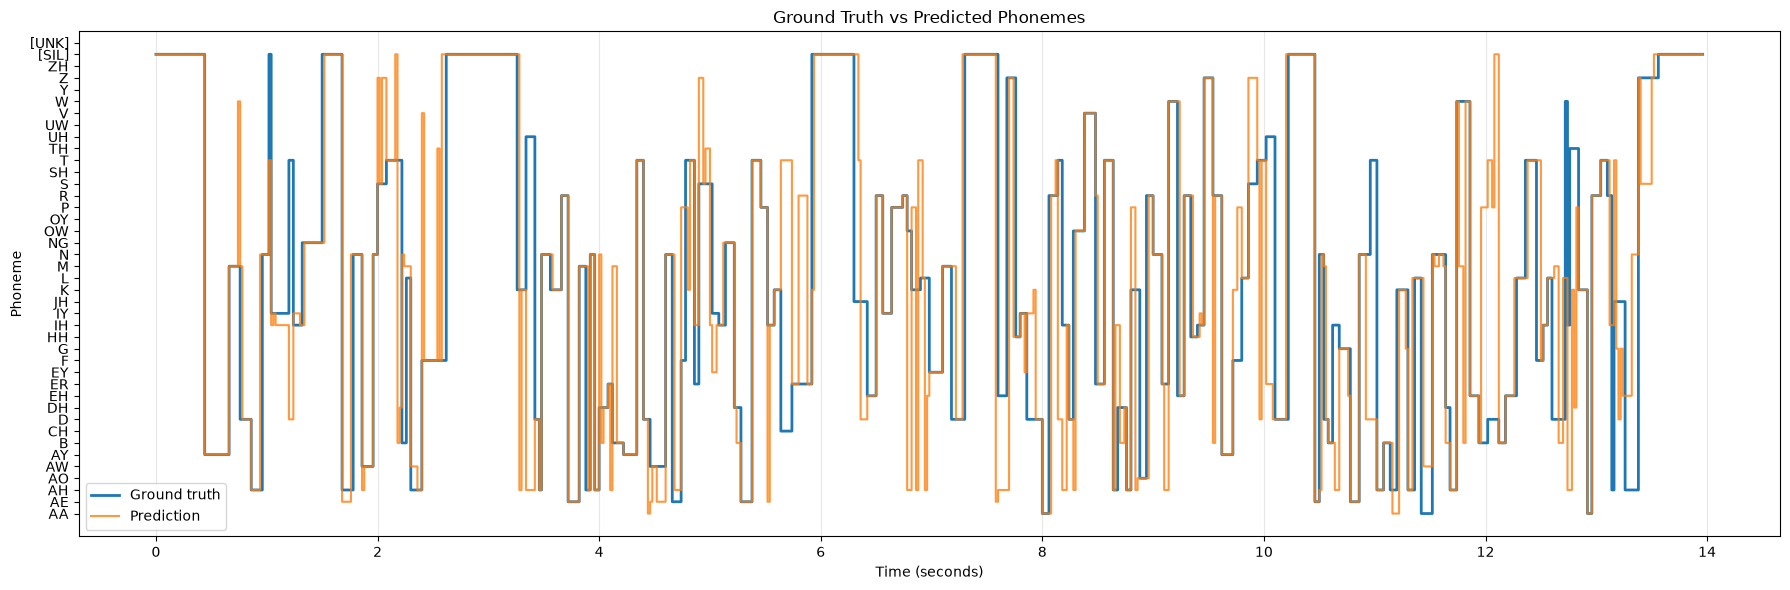

In [126]:
# ============================================
# Cell 33: Ground Truth vs Predicted Phonemes
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------
# Pick one test utterance
# --------------------------------------------

item = test_chunk_index[0]

file_id = item["file_id"]
row_id = item["row_id"]

path = parquet_files[file_id]

table = pq.read_table(
    path,
    columns=[
        "audio",
        "phones",
        "phone_starts",
        "phone_ends",
        "duration",
    ]
)

audio_entry = table["audio"][row_id].as_py()

audio = process_audio(audio_entry)

phones_true = table["phones"][row_id].as_py()
phone_starts = table["phone_starts"][row_id].as_py()
phone_ends = table["phone_ends"][row_id].as_py()

duration = table["duration"][row_id].as_py()

del table


# --------------------------------------------
# Create chunks for this utterance
# --------------------------------------------

num_chunks = int(
    np.ceil(duration / CHUNK_DURATION)
)

all_predicted_ids = []
all_true_ids = []

for chunk_id in range(num_chunks):

    X_chunk, y_chunk = create_chunk(
        audio=audio,
        phones=phones_true,
        phone_starts=phone_starts,
        phone_ends=phone_ends,
        chunk_id=chunk_id,
    )

    X_tensor = torch.from_numpy(
        X_chunk
    ).float().unsqueeze(0).to(DEVICE)

    with torch.no_grad():

        output = model(
            X_tensor
        )

        prediction = output.argmax(
            dim=-1
        ).squeeze(0).cpu().numpy()

    all_predicted_ids.extend(
        prediction
    )

    all_true_ids.extend(
        y_chunk
    )


all_predicted_ids = np.asarray(
    all_predicted_ids
)

all_true_ids = np.asarray(
    all_true_ids
)


# --------------------------------------------
# Remove padded frames
# --------------------------------------------

valid_mask = (
    all_true_ids != -100
)

all_predicted_ids = (
    all_predicted_ids[valid_mask]
)

all_true_ids = (
    all_true_ids[valid_mask]
)


# --------------------------------------------
# Convert IDs → phoneme names
# --------------------------------------------

true_labels = [
    id_to_phone[int(i)]
    for i in all_true_ids
]

predicted_labels = [
    id_to_phone[int(i)]
    for i in all_predicted_ids
]


# --------------------------------------------
# Plot
# --------------------------------------------

time_axis = (
    np.arange(len(true_labels))
    * FRAME_HOP
)

fig, ax = plt.subplots(
    figsize=(18, 6)
)

ax.step(
    time_axis,
    all_true_ids,
    where="post",
    label="Ground truth",
    linewidth=2
)

ax.step(
    time_axis,
    all_predicted_ids,
    where="post",
    label="Prediction",
    linewidth=1.5,
    alpha=0.8
)

ax.set_title(
    "Ground Truth vs Predicted Phonemes"
)

ax.set_xlabel(
    "Time (seconds)"
)

ax.set_ylabel(
    "Phoneme"
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_yticklabels(
    phones
)

ax.legend()

ax.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [119]:
# ============================================
# Continue training for 5 more epochs
# ============================================

import time
from pathlib import Path

EXTRA_EPOCHS = 5

CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for epoch in range(EXTRA_EPOCHS):

    model.train()

    running_loss = 0.0
    num_batches = 0

    start_time = time.perf_counter()

    for batch_index, (X_batch, y_batch) in enumerate(
        train_loader
    ):

        X_batch = X_batch.to(
            DEVICE,
            non_blocking=True
        )

        y_batch = y_batch.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs.reshape(-1, NUM_CLASSES),
            y_batch.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        num_batches += 1

        if (batch_index + 1) % 500 == 0:

            average_loss = (
                running_loss / num_batches
            )

            print(
                f"Epoch {epoch + 1}/{EXTRA_EPOCHS} | "
                f"Batch {batch_index + 1}/{len(train_loader)} | "
                f"Loss: {average_loss:.4f}"
            )

    epoch_loss = (
        running_loss / num_batches
    )

    epoch_time = (
        time.perf_counter() - start_time
    )

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"model_epoch_{epoch + 6}.pt"
    )

    torch.save(
        model.state_dict(),
        checkpoint_path
    )

    print(
        f"\nEpoch {epoch + 6} complete | "
        f"Loss: {epoch_loss:.4f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

    print(
        f"Saved: {checkpoint_path}"
    )

    print()

Epoch 1/5 | Batch 500/9434 | Loss: 0.7568
Epoch 1/5 | Batch 1000/9434 | Loss: 0.7278
Epoch 1/5 | Batch 1500/9434 | Loss: 0.7203
Epoch 1/5 | Batch 2000/9434 | Loss: 0.7264
Epoch 1/5 | Batch 2500/9434 | Loss: 0.7252
Epoch 1/5 | Batch 3000/9434 | Loss: 0.7325
Epoch 1/5 | Batch 3500/9434 | Loss: 0.7367
Epoch 1/5 | Batch 4000/9434 | Loss: 0.7352
Epoch 1/5 | Batch 4500/9434 | Loss: 0.7381
Epoch 1/5 | Batch 5000/9434 | Loss: 0.7368
Epoch 1/5 | Batch 5500/9434 | Loss: 0.7384
Epoch 1/5 | Batch 6000/9434 | Loss: 0.7377
Epoch 1/5 | Batch 6500/9434 | Loss: 0.7399
Epoch 1/5 | Batch 7000/9434 | Loss: 0.7411
Epoch 1/5 | Batch 7500/9434 | Loss: 0.7420
Epoch 1/5 | Batch 8000/9434 | Loss: 0.7411
Epoch 1/5 | Batch 8500/9434 | Loss: 0.7400
Epoch 1/5 | Batch 9000/9434 | Loss: 0.7399

Epoch 6 complete | Loss: 0.7399 | Time: 2.67 min
Saved: ..\checkpoints\model_epoch_6.pt

Epoch 2/5 | Batch 500/9434 | Loss: 0.7418
Epoch 2/5 | Batch 1000/9434 | Loss: 0.7290
Epoch 2/5 | Batch 1500/9434 | Loss: 0.7319
Epoch 2/5

In [127]:
# ============================================
# Evaluate epochs 6-10
# ============================================

def evaluate_checkpoint(
    checkpoint_path
):

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE
        )
    )

    model.to(DEVICE)
    model.eval()

    test_loss = 0.0
    correct_frames = 0
    total_frames = 0
    num_batches = 0

    with torch.no_grad():

        for X_batch, y_batch in test_loader:

            X_batch = X_batch.to(
                DEVICE,
                non_blocking=True
            )

            y_batch = y_batch.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(X_batch)

            loss = criterion(
                outputs.reshape(
                    -1,
                    NUM_CLASSES
                ),
                y_batch.reshape(-1)
            )

            test_loss += loss.item()
            num_batches += 1

            predictions = outputs.argmax(
                dim=-1
            )

            valid_mask = (
                y_batch != -100
            )

            correct_frames += (
                (
                    predictions[valid_mask]
                    == y_batch[valid_mask]
                )
                .sum()
                .item()
            )

            total_frames += (
                valid_mask.sum().item()
            )

    average_test_loss = (
        test_loss / num_batches
    )

    test_accuracy = (
        correct_frames / total_frames
    )

    return (
        average_test_loss,
        test_accuracy
    )


results = []

for epoch in range(6, 11):

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"model_epoch_{epoch}.pt"
    )

    test_loss, test_accuracy = (
        evaluate_checkpoint(
            checkpoint_path
        )
    )

    results.append({
        "epoch": epoch,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    })

    print(
        f"Epoch {epoch} | "
        f"Test loss: {test_loss:.4f} | "
        f"Test accuracy: "
        f"{test_accuracy * 100:.2f}%"
    )

Epoch 6 | Test loss: 0.9760 | Test accuracy: 70.14%
Epoch 7 | Test loss: 0.9755 | Test accuracy: 70.24%
Epoch 8 | Test loss: 0.9206 | Test accuracy: 71.48%
Epoch 9 | Test loss: 0.9114 | Test accuracy: 71.89%
Epoch 10 | Test loss: 0.9300 | Test accuracy: 71.45%


In [128]:
# ============================================
# Use epoch 9 as the current best model
# ============================================

best_checkpoint = (
    CHECKPOINT_DIR
    / "model_epoch_9.pt"
)

model.load_state_dict(
    torch.load(
        best_checkpoint,
        map_location=DEVICE
    )
)

model.to(DEVICE)
model.eval()

# Save a convenient copy
torch.save(
    model.state_dict(),
    "../checkpoints/best_model.pt"
)

print("Loaded and saved epoch 9 as best_model.pt")

Loaded and saved epoch 9 as best_model.pt
